[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L5/BA_L5_recent/BA_L5_recent.ipynb)

# BA_L5_recent: The Last Twelve Weeks of the Dollar Stablecoins

*Quantlet of Lecture 5, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Hourly deviations from the 1 USD peg of USDT, USDC and DAI, and of USDC priced in USDT, from 1 August to 23 October 2026, with a band of plus or minus 15 basis points; monthly mean discount of USDT. Data: EODHD hourly aggregated prices.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

Setup: chart style and colours of the slides, and a `save()` helper that puts one legend below the figure.

In [4]:
import matplotlib
import matplotlib.dates as mdates
from scipy import stats

# the slide charts use matplotlib's default sizes with 10-point text and an 8-point legend
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 'medium', 'axes.titlesize': 'large', 'axes.linewidth': 0.8,
                     'lines.linewidth': 1.5, 'legend.fontsize': 8})
COL = {'USDT': GREEN, 'USDC': BLUE, 'DAI': GOLD}


def save(fig, name, bottom, ncol=3):
    """One legend for all panels below the plot (as on the slide), then save to OUT_PATH and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

## What the chart shows

Hourly deviations $d_t = 10^4\,(P_t - 1)$ in basis points (bp) of USDT, USDC and DAI against the US dollar (USD), and of USDC priced in USDT, $10^4(P^{\mathrm{USDC}}_t / P^{\mathrm{USDT}}_t - 1)$, from 1 August to 23 October 2026, with the $\pm 15$ bp band used as the depeg threshold.
All times are Coordinated Universal Time (UTC).

**Data:** EOD Historical Data (EODHD) hourly closing prices.

In [5]:
H = pd.concat({'USDC': hourly('USDC-USD.CC'), 'USDT': hourly('USDT-USD.CC'), 'DAI': hourly('DAI-USD.CC'),
               'BTC': hourly('BTC-USD.CC')}, axis=1)
H = H.reindex(pd.date_range('2022-01-01 00:00', '2026-10-23 23:00', freq='h'))   # regular hourly grid, lecture sample
dh = 1e4 * (H['USDC'] / H['USDT'] - 1)                                             # USDC priced in USDT, bp
print(f'hourly grid: {H.index[0]} to {H.index[-1]} UTC, {len(H)} hours; '
      f'hours with USDC or USDT missing: {100 * H[["USDC", "USDT"]].isna().any(axis=1).mean():.2f}%')

hourly grid: 2022-01-01 00:00:00 to 2026-10-23 23:00:00 UTC, 42168 hours; hours with USDC or USDT missing: 2.80%


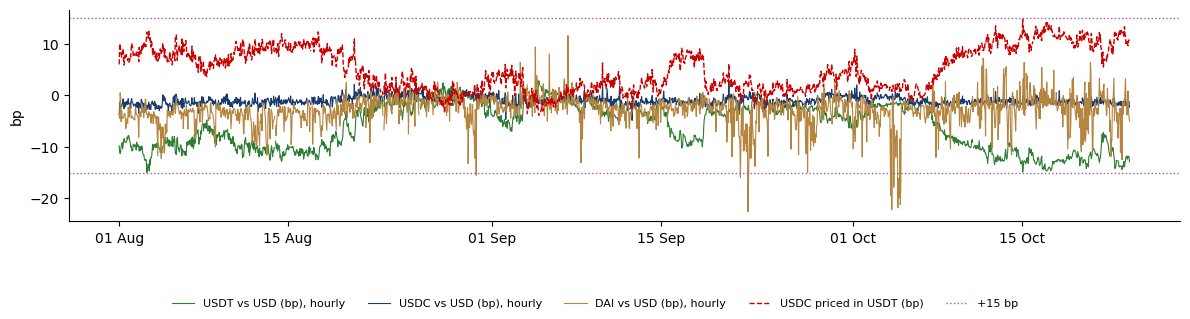

In [6]:
rec = H.loc['2026-08-01':]
fig, ax = plt.subplots(figsize=(12, 3.2))
for s in ['USDT', 'USDC', 'DAI']:
    ax.plot(rec.index, 1e4 * (rec[s] - 1), color=COL[s], lw=0.8, label=f'{s} vs USD (bp), hourly')
ax.plot(rec.index, dh.loc['2026-08-01':], color=RED, lw=1, ls='--', label='USDC priced in USDT (bp)')
ax.axhline(15, color=ETH, ls=':', lw=1, label='+15 bp')
ax.axhline(-15, color=ETH, ls=':', lw=1)
ax.set_ylabel('bp'); ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
save(fig, 'ba_l5_recent', 0.17, ncol=5)

## Key numbers

In [7]:
tt = 1e4 * (H['USDT'] - 1)
for m, a, b in [('August', '2026-08-01', '2026-08-31'), ('September', '2026-09-01', '2026-09-30'), ('October (to 23 Oct)', '2026-10-01', '2026-10-23')]:
    print(f'USDT vs USD, mean hourly deviation in {m} 2026: {tt.loc[a:b].mean():.1f} bp')
lastm = dh.loc['2026-10-01':]
print(f'\nUSDC priced in USDT, October 2026: mean {lastm.mean():.1f} bp, maximum {lastm.max():.1f} bp at {lastm.idxmax()} UTC')
print(f'hours at or above 10 bp: {int((lastm >= 10).sum())} of {len(lastm)}; hours at or above 15 bp: {int((lastm >= 15).sum())}')

USDT vs USD, mean hourly deviation in August 2026: -6.6 bp
USDT vs USD, mean hourly deviation in September 2026: -3.2 bp
USDT vs USD, mean hourly deviation in October (to 23 Oct) 2026: -8.7 bp

USDC priced in USDT, October 2026: mean 7.5 bp, maximum 14.7 bp at 2026-10-15 02:00:00 UTC
hours at or above 10 bp: 206 of 552; hours at or above 15 bp: 0


**How to read it:** USDT traded a few basis points below the dollar for three months, so USDC priced in USDT sat near 10 bp for hundreds of hours without crossing 15 bp.
A rule at 10 bp would have fired repeatedly; the price alone does not tell a persistent discount from stress.